# DINO Feature Lightweight Classifier

## Import Dependencies and Setup

In [1]:
# import system libs
import os, glob
import time
import shutil
import pathlib
import itertools
from PIL import Image

# import data handling tools
import cv2
import numpy as np
import pandas as pd
import seaborn as sns
sns.set_style('darkgrid')
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split # for fixed split
from sklearn.model_selection import StratifiedKFold, cross_validate # for cross-val

from sklearn.metrics import confusion_matrix, classification_report

import tensorflow as tf

# Ignore Warnings
import warnings
warnings.filterwarnings("ignore")



print ('modules loaded')

ModuleNotFoundError: No module named 'cv2'

In [2]:
import sys, torch
print(sys.version)
print(torch.__version__, torch.version.cuda, torch.cuda.is_available())
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no GPU")
print("TensorFlow version:", tf.__version__)

print("Available GPUs:", tf.config.list_physical_devices('GPU'))
!nvidia-smi

3.11.5 (main, Sep 11 2023, 08:31:25) [Clang 14.0.6 ]
2.14.0 None False
no GPU


NameError: name 'tf' is not defined

## Load Data

In [10]:
# mount google drive
import kagglehub
from google.colab import drive
drive.mount('/content/drive')

BASE_DIR = kagglehub.dataset_download("briscdataset/brisc2025")
# Set fixed seed
SEED = 42

Mounted at /content/drive
Using Colab cache for faster access to the 'brisc2025' dataset.


In [11]:
import importlib

sys.path.append('/content/drive/MyDrive/brain_tumor_mri_BRISC_parsed_datasets')
import helpers

importlib.reload(helpers)

from helpers import walk_dir, load_parsed_datasets


#################################
# Print data tree for reference
#################################
walk_dir(BASE_DIR, max_depth=3)

brisc2025/
  brisc2025/
  brisc2025/
    segmentation_task/
    classification_task/
    segmentation_task/
      test/
      train/
      test/
        images/
        masks/
      train/
        images/
        masks/
    classification_task/
      test/
      train/
      test/
        pituitary/
        no_tumor/
        meningioma/
        glioma/
      train/
        pituitary/
        no_tumor/
        meningioma/
        glioma/


In [12]:
dataset_dir = '/content/drive/MyDrive/brain_tumor_mri_BRISC_parsed_datasets'

#################################
# Load parsed data (using BRISC_MRI_data_parsing.ipynb and helpers.ipynb)
#################################

classification_df, classification_test_df = load_parsed_datasets(dataset_dir)

Successfully loaded classification training dataset (5000 samples) and testing dataset (1000 samples) from Drive!


## Model

In [13]:
###############################
# DEPENDENCIES
###############################

# viTransformer
from transformers import ViTImageProcessor, ViTModel

# SVM head
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC

# Added missing imports and utility for progress tracking
import joblib
from tqdm.notebook import tqdm

In [14]:
# ==========================================
# CITATION / SOURCE ATTRIBUTION
# Original code retrieved from: https://arxiv.org/abs/2104.14294
# Author: Mathilde Caron, Hugo Touvron, Ishan Misra, Herve Jegou, Julien Mairal,
#Piotr Bojanowski, Armand Joulin
# Adapted: Altered with Gemini to enhance Cuda performance
# ==========================================

########################################
# Build the DINO ViTransformer Model
#########################################


%%capture
processor = ViTImageProcessor.from_pretrained(
    'facebook/dino-vits16'
)

model = ViTModel.from_pretrained(
    'facebook/dino-vits16'
)

# freeze model param
model.eval()

# assign faster ecosystem
device = torch.device(
    'cuda' if torch.cuda.is_available() else 'cpu'
)

model.to(device)

# ==========================================
# CITATION / SOURCE ATTRIBUTION
# Implementation based on:  https://doi.org/10.3390/electronics15050952
# Author: Rim Missaoui 1,2, Marco Del Coco 3 , Wajdi Saadaoui 4, Wided Hechkel 2,
# Abdelhamid Helali, Pierluigi Carcagni, and MarcoLeo

# Original code retrieved partly from: https://arxiv.org/abs/2104.14294
# Author: Mathilde Caron, Hugo Touvron, Ishan Misra, Herve Jegou, Julien Mairal,
#Piotr Bojanowski, Armand Joulin

# Adapted: paper did not specify patch size; Chat GPT helped modify script
# ==========================================

########################################
# Aumotates DINO feature extraction
#########################################


def DINO_feature_extraction(image):

    # Convert image to RGB
    image = image.convert('RGB')

    # Preprocess image
    inputs = processor(
        images=image,
        return_tensors="pt"
    )

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    # Extract features
    with torch.inference_mode():
        outputs = model(
            **inputs,
            output_hidden_states=True
        )

    # Penultimate layer CLS token
    features = outputs.hidden_states[-2][:, 0, :]

    return features.cpu().numpy().flatten()

[transformers] ViTModel LOAD REPORT from: facebook/dino-vits16
Key                 | Status  | 
--------------------+---------+-
pooler.dense.weight | MISSING | 
pooler.dense.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [15]:
# ==========================================
# CITATION / SOURCE ATTRIBUTION
# Implementation based on:  https://doi.org/10.3390/electronics15050952
# Author: Rim Missaoui 1,2, Marco Del Coco 3 , Wajdi Saadaoui 4, Wided Hechkel 2,
# Abdelhamid Helali, Pierluigi Carcagni, and MarcoLeo
# Adapted: paper did not specify patch size; Chat GPT helped write script
# ==========================================

# Sample one path from classification_df if available to prevent NameError
if not classification_df.empty:
    sample_image_path = classification_df['filepaths'].iloc[0]
    image = Image.open(sample_image_path).convert('RGB')

    inputs = processor(
        images=image,
        return_tensors="pt"
    )

    outputs = model(**inputs, output_hidden_states=True)

    last_hidden_states = outputs.last_hidden_state

    # penultimate-layer features
    features = outputs.hidden_states[-2][:, 0, :]
    print("DINO extract successful. Extracted shape:", features.shape)
else:
    print("Dataset dataframe is empty. Please load dataset first.")

DINO extract successful. Extracted shape: torch.Size([1, 384])


In [16]:
###############################
# SVM Head
###############################

# ==========================================
# CITATION / SOURCE ATTRIBUTION
# Original code retrieved from: https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html
# Author: Rim Missaoui 1,2, Marco Del Coco 3 , Wajdi Saadaoui 4, Wided Hechkel 2,
# Abdelhamid Helali, Pierluigi Carcagni, and MarcoLeo

# Implementation based on: https://doi.org/10.3390/electronics15050952
# Adapted: Modifications performed using OpenAI ChatGPT
# ==========================================
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline

svm_model = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=0.90, svd_solver='full')),
    ('svm', SVC(
        kernel='rbf',
        C=10,
        gamma='scale',
        class_weight='balanced'
    ))
])

## Extract DINO features

In [18]:
#################################
# Create a checkpoint directory
#################################

checkpoint_dir = '/content/drive/MyDrive/brain_tumor_checkpoints'

os.makedirs(checkpoint_dir, exist_ok=True)

In [ ]:
######################################################
# Extraction of features from 5000 training images
######################################################

print("Extracting training features...")
X_train = np.stack([
    DINO_feature_extraction(Image.open(path))
    # tqdm tracks extraction progress
    for path in tqdm(classification_df['filepaths'], desc="Extracting Train Features")
])

# Keep the original 4-class ground truth labels
y_train = classification_df['labels'].values

######################################################
# Extraction of features from 1000 test images
######################################################

print("Extracting test features...")
X_test = np.stack([
    DINO_feature_extraction(Image.open(path))
    for path in tqdm(classification_test_df['filepaths'], desc="Extracting Test Features")
])

# Keep the original 4-class ground truth labels
y_test = classification_test_df['labels'].values

######################################################
# Save extracted features in checkpoint
######################################################
# Save DINO extracted training features
np.savez_compressed(
    os.path.join(checkpoint_dir, 'dino_training_features.npz'),
    X_train=X_train,
    y_train=y_train
)

np.savez_compressed(
    os.path.join(checkpoint_dir, 'dino_test_features.npz'),
    X_test=X_test,
    y_test=y_test
)
print(f"Saved test features to {os.path.join(checkpoint_dir, 'dino_test_features.npz')}")

Extracting training features...


Extracting Train Features:   0%|          | 0/5000 [00:00<?, ?it/s]

Extracting test features...


Extracting Test Features:   0%|          | 0/1000 [00:00<?, ?it/s]

Saved test features to /content/drive/MyDrive/brain_tumor_checkpoints/dino_test_features.npz


In [ ]:
from PIL import Image

rng = np.random.default_rng(SEED)
rotated_features = []

for path in tqdm(classification_df["filepaths"], desc="Extracting rotated MRI features"):
    with Image.open(path) as scan:
        angle = float(rng.uniform(-10, 10))
        rotated = scan.convert("RGB").rotate(angle, resample=Image.Resampling.BILINEAR, fillcolor=0)
        rotated_features.append(DINO_feature_extraction(rotated))

X_rotated = np.stack(rotated_features)
assert X_rotated.shape == X_train.shape

In [2]:
##############################################################
# LOAD PRE-EXTRACTED TRAINING FEATURES TO AVOID RE-EXTRACTION
##############################################################
import numpy as np
import os

train_features_path = os.path.join(checkpoint_dir, 'dino_training_features.npz')
test_features_path = os.path.join(checkpoint_dir, 'dino_test_features.npz')

# Load Train Features - allow_pickle=True is required for object arrays (string labels)
if os.path.exists(train_features_path):
    train_data = np.load(train_features_path, allow_pickle=True)
    X_train = train_data['X_train']
    y_train = train_data['y_train']
    print(f"Successfully loaded X_train: {X_train.shape}, y_train: {y_train.shape}")
else:
    print("Train feature archive not found. Please run the training extraction cell above first.")

# ==========================================
# CITATION / SOURCE ATTRIBUTION
# Implementation based on: https://doi.org/10.3390/electronics15050952
# Author: Rim Missaoui 1,2, Marco Del Coco 3 , Wajdi Saadaoui 4, Wided Hechkel 2,
# Abdelhamid Helali, Pierluigi Carcagni, and MarcoLeo
#
# Adapted: Modifications were with ChatGPT
# ==========================================


######################################################
# 5 fold cross-validation to verify hyperparameter performance
######################################################

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

print("Running cross-validation...")
from sklearn.base import clone
from sklearn.metrics import accuracy_score, f1_score

rows = []
for fold, (train, val) in enumerate(cv.split(X_train, y_train), start=1):
    for use_rotation in (False, True):
        X_fit, y_fit = X_train[train], y_train[train]
        if use_rotation:
            X_fit = np.concatenate([X_fit, X_rotated[train]])
            y_fit = np.concatenate([y_fit, y_train[train]])

        fitted = clone(svm_model).fit(X_fit, y_fit)
        pred = fitted.predict(X_train[val])
        rows.append({
            "fold": fold,
            "rotation": use_rotation,
            "accuracy": accuracy_score(y_train[val], pred),
            "macro_f1": f1_score(y_train[val], pred, average="macro"),
        })

comparison = pd.DataFrame(rows)
display(comparison.groupby("rotation")[["accuracy", "macro_f1"]].mean())bs=-1
)

######################################################
#  Save Results and Checkpoints
######################################################

results_df = pd.DataFrame(results)
results_df.to_csv(
    os.path.join(checkpoint_dir, 'DINO_SVM_results.csv'),
    index=False
)

##########################################################
#  Final SVM fit to entire dataset and save to checkpoint
##########################################################

print("Fitting final SVM model...")
svm_model.fit(X_train, y_train)

# Save final pipeline using joblib
joblib.dump(
    svm_model,
    os.path.join(checkpoint_dir, 'dino_svm_final.pkl')
)
print("Training process completed successfully!")

SyntaxError: unmatched ')' (260409370.py, line 62)

In [20]:
for metric in ['accuracy', 'precision_macro', 'recall_macro', 'f1_macro']:
    scores = results[f'test_{metric}']

    print(
        f'{metric}: {scores.mean():.4f} '
        f'+/- {scores.std():.4f}'
    )

accuracy: 0.9822 +/- 0.0058
precision_macro: 0.9832 +/- 0.0051
recall_macro: 0.9818 +/- 0.0064
f1_macro: 0.9824 +/- 0.0059


## Testing

In [21]:
###################################
# Load fitted DINO-SVM model
###################################
fitted_SVM_model_path = os.path.join(checkpoint_dir, 'dino_svm_final.pkl')

if os.path.exists(fitted_SVM_model_path):
    svm_model = joblib.load(fitted_SVM_model_path)
    print("Successfully loaded fitted SVM model!")

##############################################################
# LOAD PRE-EXTRACTED TESTING FEATURES TO AVOID RE-EXTRACTION
##############################################################

# Load Test Features - allow_pickle=True is required for object arrays (string labels)
if os.path.exists(test_features_path):
    test_data = np.load(test_features_path, allow_pickle=True)
    X_test = test_data['X_test']
    y_test = test_data['y_test']
    print(f"Successfully loaded X_test: {X_test.shape}, y_test: {y_test.shape}")
else:
    print("Test feature archive not found. Please run the test extraction cell above first.")


Successfully loaded fitted SVM model!
Successfully loaded X_test: (1000, 384), y_test: (1000,)


Classification Report (4-class Multi-class Tumor Classifier):
              precision    recall  f1-score   support

      glioma       0.99      0.97      0.98       254
  meningioma       0.98      0.98      0.98       306
    no_tumor       1.00      1.00      1.00       140
   pituitary       0.99      1.00      1.00       300

    accuracy                           0.99      1000
   macro avg       0.99      0.99      0.99      1000
weighted avg       0.99      0.99      0.99      1000



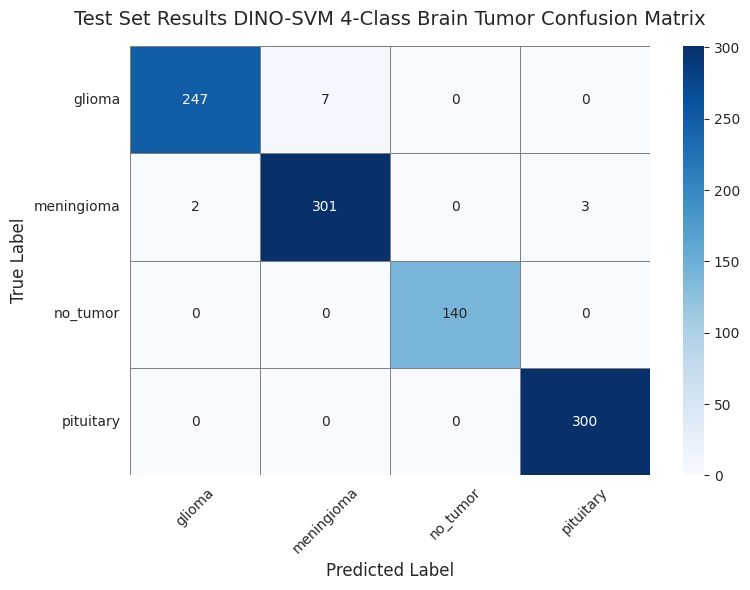

In [22]:
###########################################
# Evaluation Metrics and CONFUSION MATRIX
###########################################

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
import pandas as pd

# Predict using loaded features
y_pred = svm_model.predict(X_test)
unique_labels = sorted(list(set(y_test)))

# Generate classification report
print("Classification Report (4-class Multi-class Tumor Classifier):")
print(classification_report(
    y_test,
    y_pred,
    labels=unique_labels,
    zero_division=0
))

# Compute Confusion Matrix
conf_matrix = confusion_matrix(y_test, y_pred, labels=unique_labels)
conf_matrix_df = pd.DataFrame(conf_matrix, index=unique_labels, columns=unique_labels)

# Plot Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(
    conf_matrix_df,
    annot=True,
    fmt='d',
    cmap='Blues',
    cbar=True,
    linewidths=0.5,
    linecolor='gray'
)
plt.title('Test Set Results DINO-SVM 4-Class Brain Tumor Confusion Matrix', fontsize=14, pad=15)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Plotting SVM Validation Curves
Since standard SVMs do not train in iterative epochs, we cannot plot standard epoch-wise learning curves. Instead, we can plot a **Validation Curve** to see how changing a hyperparameter (such as the regularization parameter `C`) affects training and validation scores to find the sweet spot between underfitting and overfitting.

Calculating validation curve scores (this might take a moment)...


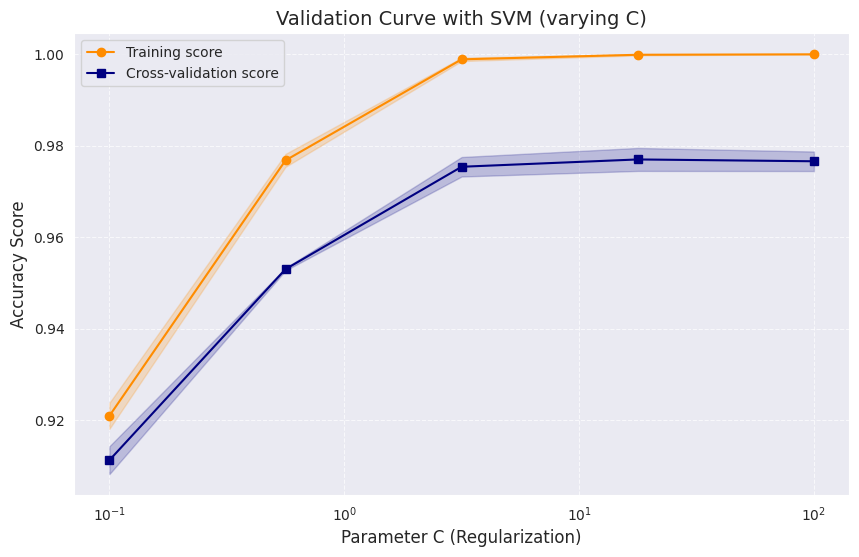

In [23]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import validation_curve

# Define parameter range to search over
param_range = np.logspace(-1, 2, 5)

print("Calculating validation curve scores (this might take a moment)...")
# Compute training and test scores over the parameter range
train_scores, test_scores = validation_curve(
    svm_model,
    X_train,
    y_train,
    param_name="svm__C",
    param_range=param_range,
    cv=3,
    scoring="accuracy",
    n_jobs=-1
)

# Calculate mean and standard deviation
train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)
test_std = np.std(test_scores, axis=1)

# Plot the Validation Curve
plt.figure(figsize=(10, 6))
plt.plot(param_range, train_mean, label="Training score", color="darkorange", marker='o')
plt.fill_between(param_range, train_mean - train_std, train_mean + train_std, alpha=0.2, color="darkorange")
plt.plot(param_range, test_mean, label="Cross-validation score", color="navy", marker='s')
plt.fill_between(param_range, test_mean - test_std, test_mean + test_std, alpha=0.2, color="navy")

plt.title("Validation Curve with SVM (varying C)", fontsize=14)
plt.xlabel("Parameter C (Regularization)", fontsize=12)
plt.ylabel("Accuracy Score", fontsize=12)
plt.semilogx()
plt.legend(loc="best")
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

Next steps: will informing a segmentation pipeline of the type of tumor improve its performance.

Which augmentations strategies work best.

Can we transform the images to increase contrast of tumor boundaries improving segmentation performance

Have a text model output recommendations based on the results to the patient. \

Alter thresholds to increase FP > FN

# Test on a single image for debugging

Predicted Label: no_tumor
Actual Label:    no_tumor

SVM Decision Function Scores:
glioma: -0.2466
meningioma: 2.1443
no_tumor: 3.2584
pituitary: 0.8076


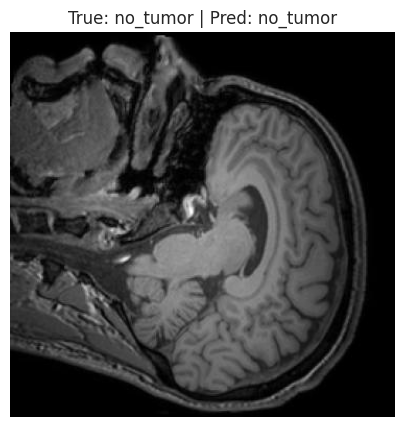

In [39]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image


##################################
# Predict label for a random image
##################################

random_idx = np.random.randint(len(X_test))

single_prediction = svm_model.predict(X_test[random_idx].reshape(1, -1))
predicted_label = single_prediction[0]
actual_label = y_test[random_idx]

print("Predicted Label:", predicted_label)
print("Actual Label:   ", actual_label)

##################################
# Get prediction scores
##################################
scores = svm_model.decision_function(X_test[random_idx].reshape(1, -1))[0]
print("\nSVM Decision Function Scores:")
for class_name, score in zip(svm_model.classes_, scores):
  print(f"{class_name}: {score:.4f}")
# ==========================================
# CITATION / SOURCE ATTRIBUTION
# Display image code generated/adapted with assistance from: Gemini (AI Assistant)
# Developer: Google
# License: Creative Commons Attribution 4.0 International
# =========================================
##################################
# Display the corresponding image
##################################
test_img_path = classification_test_df['filepaths'].iloc[random_idx]
img = Image.open(test_img_path).convert('L')

plt.figure(figsize=(5, 5))
plt.imshow(img, cmap='gray')
plt.title(f"True: {actual_label} | Pred: {predicted_label}")
plt.axis('off')
plt.show()